In [2]:
import yfinance as yf
import numpy as np
import pandas as pd
from datetime import datetime, timedelta
from scipy.optimize import minimize

In [3]:
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

TICKERS = ["FFC.KA", "MEBL.KA", "PSO.KA", "DGKC.KA", "UBL.KA", "INDU.KA", "OGDC.KA"]
END   = datetime.today()
START = END - timedelta(days = 10*365)
TRADING_DAYS = 252
RISK_FREE = 0.045

In [4]:
data = yf.download(TICKERS, start=START, end=END, auto_adjust=True, progress=False)
prices = data["Close"].ffill().dropna()
prices.tail()

Ticker,DGKC.KA,FFC.KA,INDU.KA,MEBL.KA,OGDC.KA,PSO.KA,UBL.KA
Date,,,,,,,
2026-11-03,185.0300,554.1454,"1,804.5006",526.5700,303.6300,349.9000,412.6700
2026-11-04,195.0100,562.5200,"1,814.2400",538.4800,310.4700,359.4700,422.0000
2026-11-05,203.1900,562.5200,"1,821.7000",555.0200,310.4700,362.8200,422.0000
2026-11-06,200.4100,562.6200,"1,822.3600",550.2500,312.8900,355.1000,425.3400
2026-11-10,213.5100,574.8600,"1,846.4600",570.7800,317.0200,361.3300,445.3000


In [5]:
print(START)

2016-11-13 11:14:34.299749


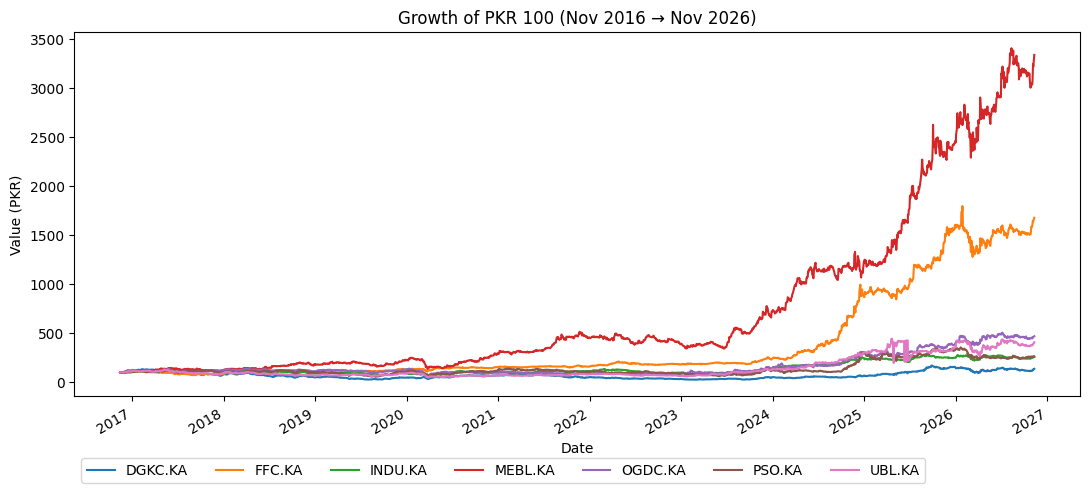

In [6]:
import matplotlib.pyplot as plt

norm = prices / prices.iloc[0] * 100
ax = norm.plot(figsize=(11, 5), linewidth=1.5)
ax.set_title("Growth of PKR 100 (Nov 2016 → Nov 2026)")
ax.set_ylabel("Value (PKR)")
ax.legend(loc="upper left", ncol=7, bbox_to_anchor=(0, -0.15))
plt.tight_layout(); plt.show()

In [7]:
log_returns = np.log(prices / prices.shift(1)).dropna()

mean_annual = log_returns.mean() * TRADING_DAYS
cov_annual  = log_returns.cov() * TRADING_DAYS
vol_annual  = np.sqrt(np.diag(cov_annual))

stock_metrics = pd.DataFrame({
    "Annual Return": mean_annual,
    "Annual Volatility": vol_annual,
    "Sharpe": (mean_annual - RISK_FREE) / vol_annual,
})
stock_metrics

,Annual Return,Annual Volatility,Sharpe
Ticker,,,
DGKC.KA,0.0294,0.4062,-0.0384
FFC.KA,0.2747,0.2441,0.9410
INDU.KA,0.0912,0.2512,0.1841
MEBL.KA,0.3418,0.2884,1.0294
OGDC.KA,0.1504,0.3171,0.3322
PSO.KA,0.0937,0.3417,0.1425
UBL.KA,0.1368,0.6485,0.1415


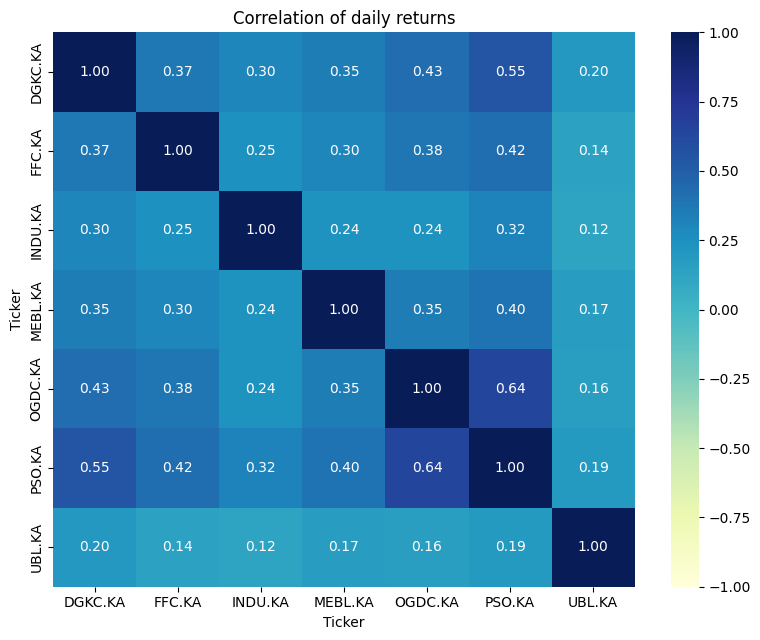

In [8]:
import seaborn as sns
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(log_returns.corr(), annot=True, fmt=".2f", cmap="YlGnBu", vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlation of daily returns")
plt.tight_layout(); plt.show()

In [9]:
def portfolio_perf(w, mean=mean_annual, cov=cov_annual, rf=RISK_FREE):
    ret = w @ mean
    vol = np.sqrt(w @ cov @ w)
    return ret, vol, (ret - rf) / vol

np.random.seed(42)
N = 20_000
n = len(TICKERS)
results = np.zeros((3, N))
for i in range(N):
    w = np.random.random(n); w /= w.sum()
    results[:, i] = portfolio_perf(w)

mc = pd.DataFrame(results.T, columns=["return", "volatility", "sharpe"])
mc.describe().round(4)

,return,volatility,sharpe
count,"20,000.0000","20,000.0000","20,000.0000"
mean,0.1598,0.2356,0.4948
std,0.0240,0.0216,0.1268
min,0.0796,0.1835,0.1124
25%,0.1437,0.2207,0.4077
50%,0.1599,0.2332,0.4908
75%,0.1756,0.2477,0.5758
max,0.2589,0.4099,1.0338


In [10]:
def neg_sharpe(w):
  return -portfolio_perf(w)[2]
def port_vol(w):
  return portfolio_perf(w)[1]
def port_ret(w):
  return portfolio_perf(w)[0]

bounds = [(0, 1)] * n
initial_weights = np.repeat(1/n, n)
constraints = {"type": "eq", "fun": lambda w: np.sum(w) - 1}

opt_max_sharpe = minimize(neg_sharpe, initial_weights, method="SLSQP", bounds=bounds, constraints=[constraints])
opt_min_var    = minimize(port_vol,   initial_weights, method="SLSQP", bounds=bounds, constraints=[constraints])

w_max_sharpe = opt_max_sharpe.x
w_min_var    = opt_min_var.x
w_equal      = initial_weights.copy()

def portfolio_summary(w, label):
    r, v, s = portfolio_perf(w)
    return {"Strategy": label, "Return": r, "Volatility": v, "Sharpe": s,
            **dict(zip(TICKERS, w.round(4)))}

portfolios = pd.DataFrame([
    portfolio_summary(w_equal,      "Equal-Weight"),
    portfolio_summary(w_min_var,    "Min Variance"),
    portfolio_summary(w_max_sharpe, "Max Sharpe"),
])
portfolios

,Strategy,Return,Volatility,Sharpe,FFC.KA,MEBL.KA,PSO.KA,DGKC.KA,UBL.KA,INDU.KA,OGDC.KA
0,Equal-Weight,0.1597,0.2258,0.5080,0.1429,0.1429,0.1429,0.1429,0.1429,0.1429,0.1429
1,Min Variance,0.2079,0.1814,0.8977,0.0000,0.3396,0.3529,0.1902,0.0958,0.0000,0.0215
2,Max Sharpe,0.3083,0.2152,1.2234,0.0000,0.5002,0.0000,0.4998,0.0000,0.0000,0.0000


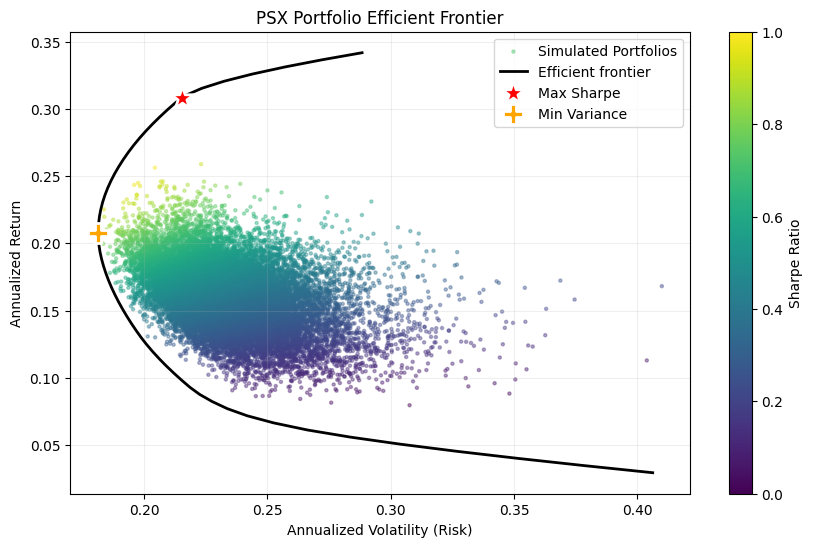

In [11]:
target_returns = np.linspace(mean_annual.min(), mean_annual.max(), 60)
ef_vol = []
for tr in target_returns:
    cons = [constraints, {"type": "eq", "fun": lambda w, tr=tr: port_ret(w) - tr}]
    res = minimize(port_vol, initial_weights, method="SLSQP", bounds=bounds, constraints=cons)
    ef_vol.append(res.fun if res.success else np.nan)
ef_vol = np.array(ef_vol)

plt.figure(figsize=(10, 6))
plt.scatter(mc.volatility, mc["return"], c=mc.sharpe, cmap="viridis", s=5, alpha=0.4, label='Simulated Portfolios')
plt.plot(ef_vol, target_returns, "k-", lw=2, label="Efficient frontier")

mr, mv, _ = portfolio_perf(w_max_sharpe)
nr, nv, _ = portfolio_perf(w_min_var)
plt.scatter(mv, mr, color="red",   s=300, marker="*", label="Max Sharpe", zorder=5, ec="white", lw=2)
plt.scatter(nv, nr, color="orange",s=200, marker="P", label="Min Variance",  zorder=5, ec="white", lw=2)

plt.xlabel("Annualized Volatility (Risk)")
plt.ylabel("Annualized Return")
plt.title("PSX Portfolio Efficient Frontier")
plt.legend()
plt.colorbar(label="Sharpe Ratio")
plt.grid(alpha=0.2)

plt.show()

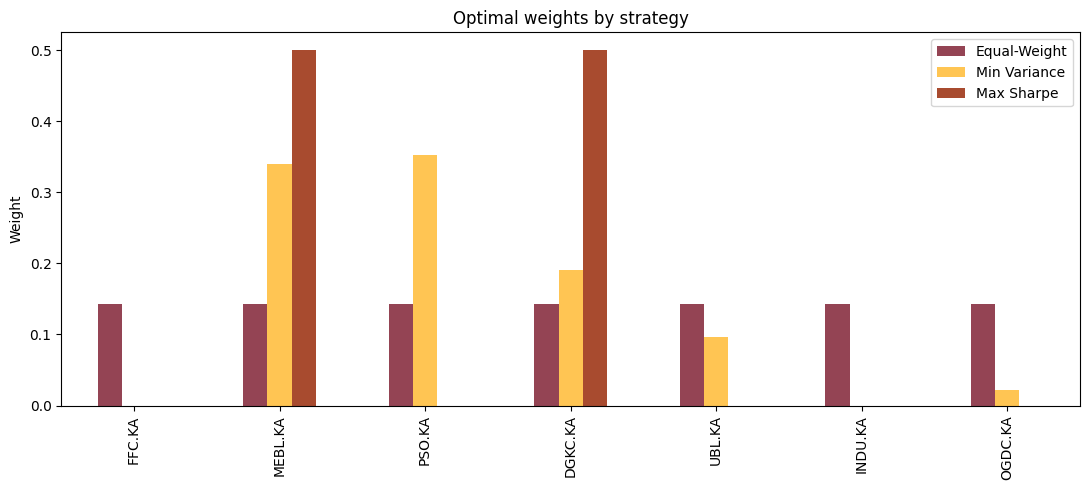

In [12]:
alloc = pd.DataFrame({
    "Equal-Weight": w_equal,
    "Min Variance": w_min_var,
    "Max Sharpe":   w_max_sharpe,
}, index=TICKERS)
alloc.plot(kind="bar", figsize=(11, 5), color=["#944454", "#FFC553", "#A84B2F"])
plt.title("Optimal weights by strategy")
plt.ylabel("Weight")
plt.legend()
plt.tight_layout()
plt.show()

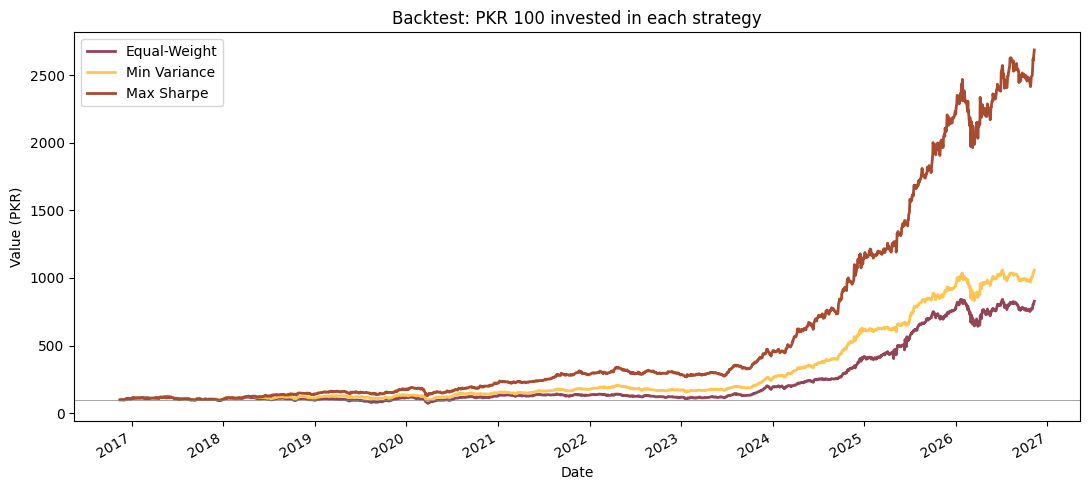

In [13]:
daily_returns = prices.pct_change().dropna()

def bt(w):
    return (daily_returns * w).sum(axis=1)

cum = pd.DataFrame({
    "Equal-Weight": (1 + bt(w_equal)).cumprod(),
    "Min Variance": (1 + bt(w_min_var)).cumprod(),
    "Max Sharpe":   (1 + bt(w_max_sharpe)).cumprod(),
})
(cum * 100).plot(figsize=(11, 5), color=["#944454", "#FFC553", "#A84B2F"], lw=2)
plt.axhline(100, color="gray", lw=0.5)
plt.title("Backtest: PKR 100 invested in each strategy"); plt.ylabel("Value (PKR)")
plt.tight_layout(); plt.show()

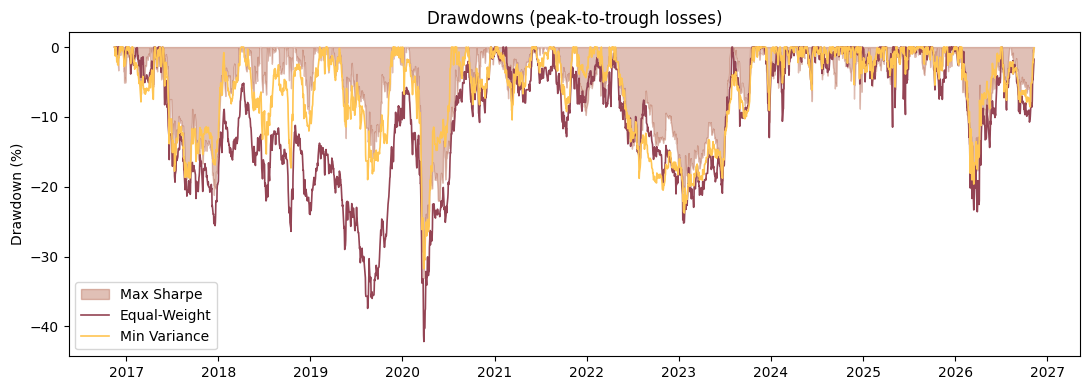

In [14]:
def drawdown(s): return (s - s.cummax()) / s.cummax()
dd = pd.DataFrame({c: drawdown(cum[c]) for c in cum.columns})

fig, ax = plt.subplots(figsize=(11, 4))
ax.fill_between(dd.index, dd["Max Sharpe"]*100, 0, color="#A84B2F", alpha=0.35, label="Max Sharpe")
ax.plot(dd.index, dd["Equal-Weight"]*100, color="#944454", lw=1.2, label="Equal-Weight")
ax.plot(dd.index, dd["Min Variance"]*100, color="#FFC553", lw=1.2, label="Min Variance")
ax.set_title("Drawdowns (peak-to-trough losses)"); ax.set_ylabel("Drawdown (%)")
ax.legend(); plt.tight_layout(); plt.show()

In [15]:
def summary(r, label):
    ann_ret = (1 + r).prod() ** (TRADING_DAYS / len(r)) - 1
    ann_vol = r.std() * np.sqrt(TRADING_DAYS)
    return {
        "Strategy": label,
        "Total Return": (1 + r).prod() - 1,
        "Annualized Return": ann_ret,
        "Annualized Volatility": ann_vol,
        "Sharpe": (ann_ret - RISK_FREE) / ann_vol,
        "Max Drawdown": drawdown((1 + r).cumprod()).min(),
    }

pd.DataFrame([
    summary(bt(w_equal),      "Equal-Weight"),
    summary(bt(w_min_var),    "Min Variance"),
    summary(bt(w_max_sharpe), "Max Sharpe"),
]).round(4)

,Strategy,Total Return,Annualized Return,Annualized Volatility,Sharpe,Max Drawdown
0,Equal-Weight,7.2721,0.2287,0.2293,0.8012,-0.4216
1,Min Variance,9.5791,0.2585,0.1817,1.1752,-0.3173
2,Max Sharpe,25.8625,0.3782,0.2160,1.5426,-0.3306
